In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score,
recall_score, f1_score, confusion_matrix)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt

In [4]:
from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/tourism_dataset_5000.csv')

Mounted at /content/drive


In [5]:
# Pré-processamento dos Dados
# Separando features e target
X = df.drop('Satisfaction', axis=1)
y = df['Satisfaction']

In [6]:
# Identificando colunas numéricas e categóricas
numeric_features = X.select_dtypes(include=['int64','float64']).columns
categorical_features = X.select_dtypes(include=['object','category']).columns

In [7]:
# Criando transformers para pré-processamento
numeric_transformer = Pipeline(
  steps=[
      ('imputer', SimpleImputer(strategy='median')), # Imputação  de valores faltantes
      ('scaler', StandardScaler()) # Escalonamento
  ]
)

In [8]:
categorical_transformer = Pipeline(
  steps=[
      ('imputer', SimpleImputer(strategy='constant', fill_value='missing')), # Imputação de valores faltantes
      ('onehot', OneHotEncoder(handle_unknown='ignore')) #one-hot transformação de categorias em números binários [0 ou 1]
  ]
)

In [9]:
# Combinando transformers em um ColumnTransformer
preprocessor = ColumnTransformer(
  transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
  ]
)

In [10]:
# Divisão dos Dados em Treino e Teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
# Seleção do Modelo
model = RandomForestClassifier(n_estimators=100, random_state=42)

In [12]:
# Criando a Pipeline completa
pipeline = Pipeline(
  steps=[
    ('preprocessor', preprocessor),
    ('classifier', model)
  ]
)

In [13]:
#Treinamento do Modelo
pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Tourist ID', 'Age', 'Preferred Tour Duration', 'Tour Duration',
       'Route ID', 'Tourist Rating', 'System Response Time',
       'Recommendation Accuracy', 'VR Experience Quality'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['Interests', 'Site Name', 'Sites Visited'], dtype='object'))])),
                ('classifier', RandomForestClassifier(random_state=42))])

In [14]:
# Avaliação do Modelo
y_pred = pipeline.predict(X_test)
y_pred_proba = pipeline.predict_proba(X_test)[:, 1] # Probabilidades para a classe positiva

In [15]:
# Métricas de Classificação
print(f'Acurácia: {accuracy_score(y_test, y_pred)}')
print(f'Precisão: {precision_score(y_test, y_pred, average="macro")}')
print(f'Recall: {recall_score(y_test, y_pred, average="macro")}')
print(f'F1-Score: {f1_score(y_test, y_pred, average="macro")}')

Acurácia: 1.0
Precisão: 1.0
Recall: 1.0
F1-Score: 1.0


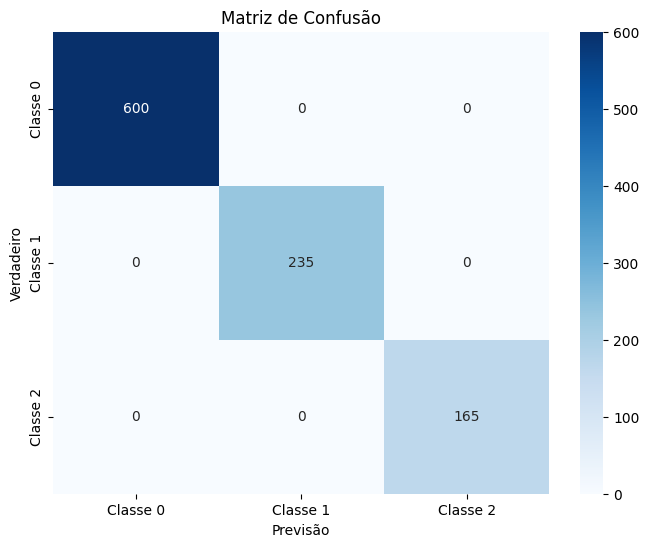

In [16]:
# Matriz de confusão
cm = confusion_matrix(y_test, y_pred)
classes = ['Classe 0', 'Classe 1', 'Classe 2']

# Plotando a matriz de confusão
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
xticklabels=classes, yticklabels=classes)
plt.title('Matriz de Confusão')
plt.xlabel('Previsão')
plt.ylabel('Verdadeiro')
plt.show()

In [17]:
# Testando uma nova entrada
# Exemplo: utilizar a primeira linha do dataset
nova_amostra = X.iloc[[0]].copy()

print("Dados utilizados para o teste:")
print(nova_amostra)

# Realizando a previsão
previsao = pipeline.predict(nova_amostra)

# Probabilidades de cada classe
probabilidades = pipeline.predict_proba(nova_amostra)

print("\nClasse prevista:")
print(previsao[0])

print("\nProbabilidade de cada classe:")
for classe, prob in zip(pipeline.classes_, probabilidades[0]):
  print(f"{classe}: {prob:.2%}")

Dados utilizados para o teste:
   Tourist ID  Age                           Interests  \
0           1   48  ['Architecture', 'Art', 'History']   

   Preferred Tour Duration  Accessibility     Site Name  \
0                        5          False  Eiffel Tower   

                                       Sites Visited  Tour Duration  Route ID  \
0  ['Eiffel Tower', 'Great Wall of China', 'Taj M...              7      1000   

   Tourist Rating  System Response Time  Recommendation Accuracy  \
0             1.6                  3.73                       97   

   VR Experience Quality  
0                    4.5  

Classe prevista:
3

Probabilidade de cada classe:
3: 98.00%
4: 2.00%
5: 0.00%
